In [176]:
import os
from dataclasses import dataclass, field

import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
from datetime import datetime

# Question 1

In [177]:
def load(filename):
    oput = {"time":[], "wspeed":[], "wah":[], "wtemp":[], "atemp":[]}
    with open(filename,"r") as f:
        for line in f:
            if line[0] != "#":
                line = line.split()
                time = datetime(int(line[0]), int(line[1]), int(line[2]), int(line[3]), int(line[4]))
                time = np.datetime64(time, 's')
                oput["time"].append(time)
                oput["wspeed"].append(float(line[6]))
                oput["wah"].append(float(line[8]))
                oput["wtemp"].append(float(line[-4]))
                oput["atemp"].append(float(line[-5]))
    return oput

In [178]:
d2015 = load("46047h2015.txt")
d2016 = load("46047h2016.txt")





#since every column has different missing data, need to define different arrays for each parameter




In [179]:
filtered = [(x, p) for x, p in zip(d2015["time"], d2015["wspeed"]) if p != 99.00]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d15_wspeed = np.array([filtered_time, filtered_val])

filtered = [(x, p) for x, p in zip(d2015["time"], d2015["wah"]) if p != 99.00]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d15_wah = np.array([filtered_time, filtered_val])

filtered = [(x, p) for x, p in zip(d2015["time"], d2015["wtemp"]) if p != 999.0]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d15_wtemp = np.array([filtered_time, filtered_val])

filtered = [(x, p) for x, p in zip(d2015["time"], d2015["atemp"]) if p != 999.0]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d15_atemp = np.array([filtered_time, filtered_val])

#and for 2016
filtered = [(x, p) for x, p in zip(d2016["time"], d2016["wspeed"]) if p != 99.00]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d16_wspeed = np.array([filtered_time, filtered_val])

filtered = [(x, p) for x, p in zip(d2016["time"], d2016["wah"]) if p != 99.00]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d16_wah = np.array([filtered_time, filtered_val])

filtered = [(x, p) for x, p in zip(d2016["time"], d2016["wtemp"]) if p != 999.0]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d16_wtemp = np.array([filtered_time, filtered_val])

filtered = [(x, p) for x, p in zip(d2016["time"], d2016["atemp"]) if p != 999.0]
filtered_time = [item[0] for item in filtered]
filtered_val = [item[1] for item in filtered]
d16_atemp = np.array([filtered_time, filtered_val])

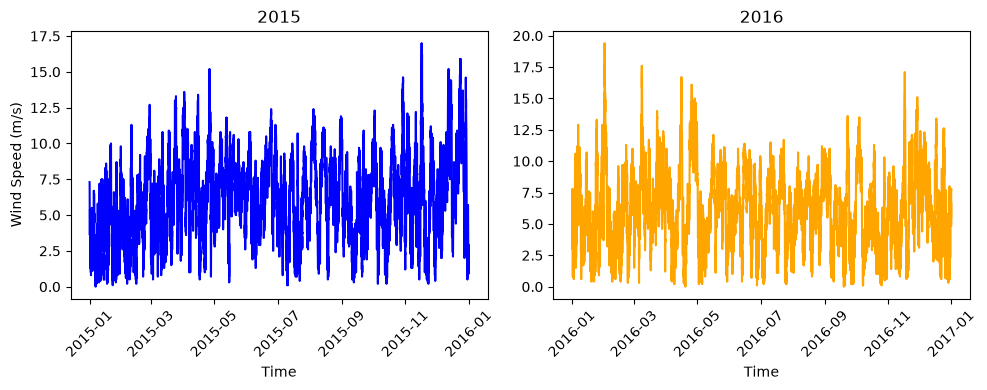

In [180]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

ax1.plot(d15_wspeed[0], d15_wspeed[1], color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Wind Speed (m/s)')

ax2.plot(d16_wspeed[0], d16_wspeed[1], color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

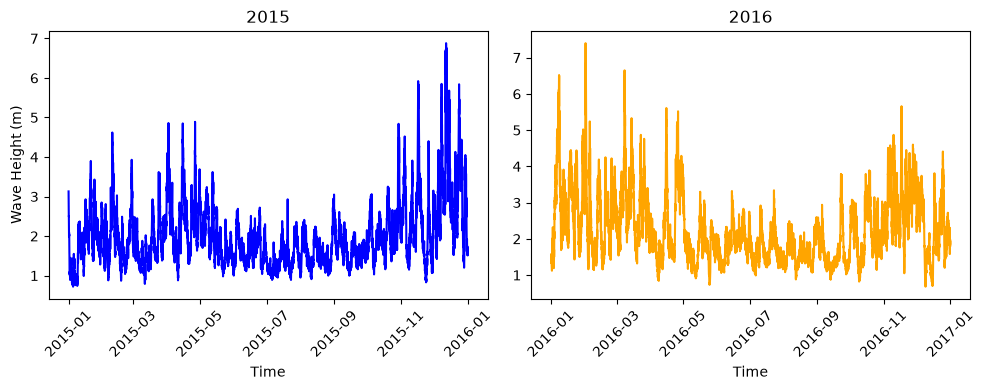

In [181]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

ax1.plot(d15_wah[0], d15_wah[1], color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Wave Height (m)')

ax2.plot(d16_wah[0], d16_wah[1], color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

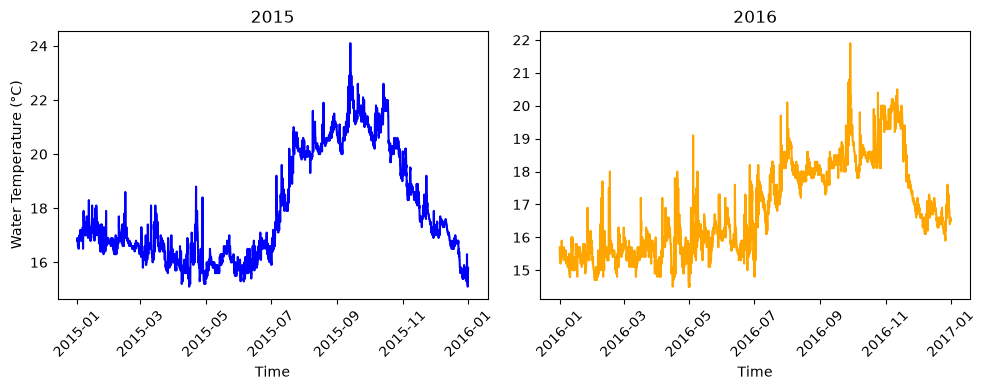

In [182]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

ax1.plot(d15_wtemp[0], d15_wtemp[1], color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Water Temperature (°C)')

ax2.plot(d16_wtemp[0], d16_wtemp[1], color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

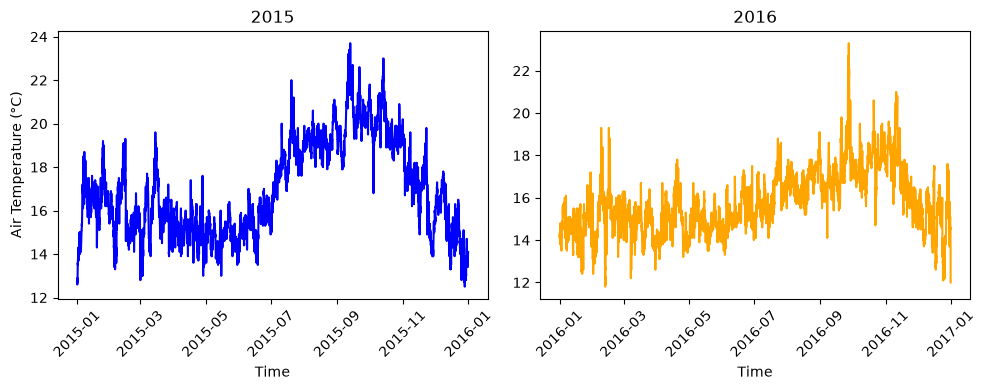

In [183]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

ax1.plot(d15_atemp[0], d15_atemp[1], color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Air Temperature (°C)')

ax2.plot(d16_atemp[0], d16_atemp[1], color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

The missing values are included in a somewhat obnoxious way, in that they have inconsistent values (either 999 or 99 with varying degrees of precision). It is necessary to separate all of the aspects of interest as a result of the missing values at different times.

# Question 2

In [184]:
def month(arr):
    month = arr[0].astype('datetime64[M]')
    temp_t = []
    temp_y = []
    temp_sd = []
    for m in np.unique(month):
        temp_t.append(m)
        temp_y.append(np.mean(arr[1][month == m]))
        sd = np.std(arr[1][month == m])
        temp_sd.append(sd/np.sqrt(4))
    arr_m = np.array([temp_t[1:], temp_y[1:], temp_sd[1:]]) #gets rid of the december prior average
    return arr_m


In [185]:
d15m_wah = month(d15_wah)
d15m_wspeed = month(d15_wspeed)
d15m_atemp = month(d15_atemp)
d15m_wtemp = month(d15_wtemp)

d16m_wah = month(d16_wah)
d16m_wspeed = month(d16_wspeed)
d16m_atemp = month(d16_atemp)
d16m_wtemp = month(d16_wtemp)

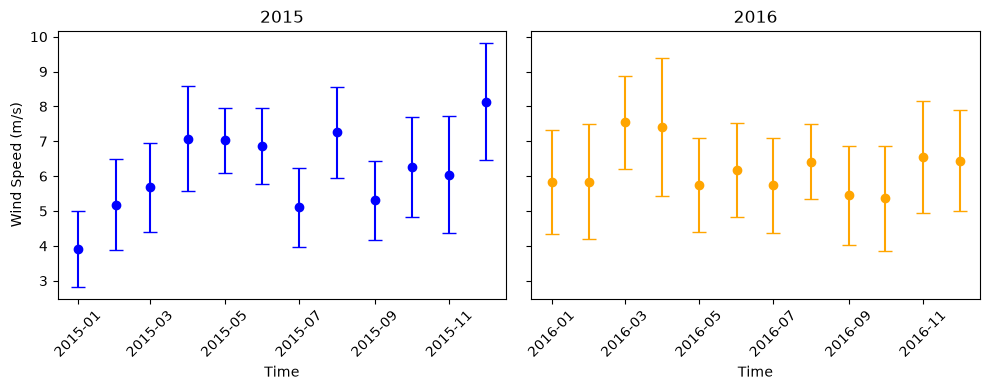

In [186]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), sharey =True)

ax1.errorbar(d15m_wspeed[0], d15m_wspeed[1], d15m_wspeed[2], fmt='o', capsize=5, color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Wind Speed (m/s)')

ax2.errorbar(d16m_wspeed[0], d16m_wspeed[1], d16m_wspeed[2],fmt='o', capsize=5, color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

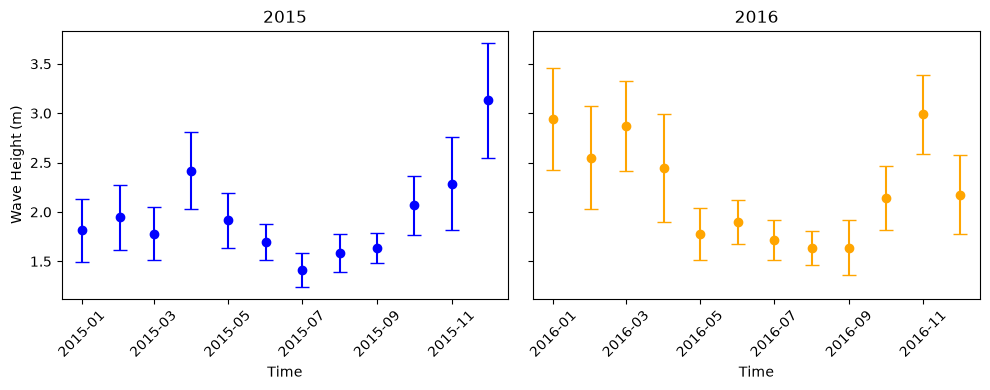

In [187]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), sharey =True)

ax1.errorbar(d15m_wah[0], d15m_wah[1], d15m_wah[2], fmt='o', capsize=5, color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Wave Height (m)')

ax2.errorbar(d16m_wah[0], d16m_wah[1], d16m_wah[2], fmt='o', capsize=5, color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

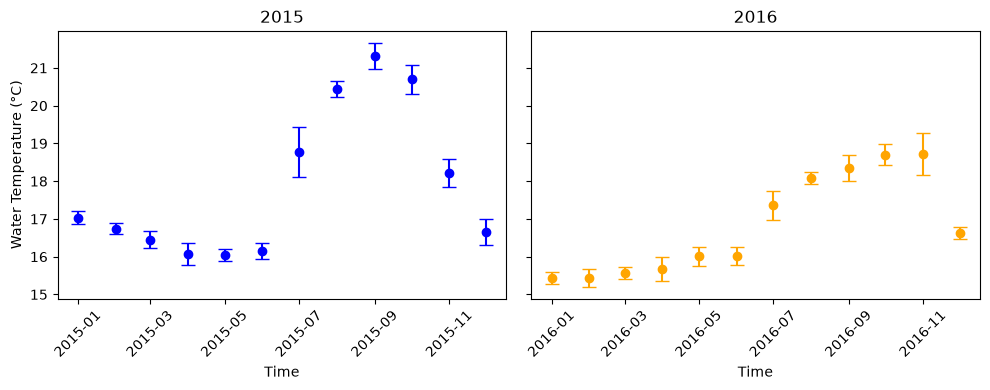

In [188]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), sharey =True)

ax1.errorbar(d15m_wtemp[0], d15m_wtemp[1], d15m_wtemp[2], fmt='o', capsize=5, color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Water Temperature (°C)')

ax2.errorbar(d16m_wtemp[0], d16m_wtemp[1], d16m_wtemp[2], fmt='o', capsize=5, color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

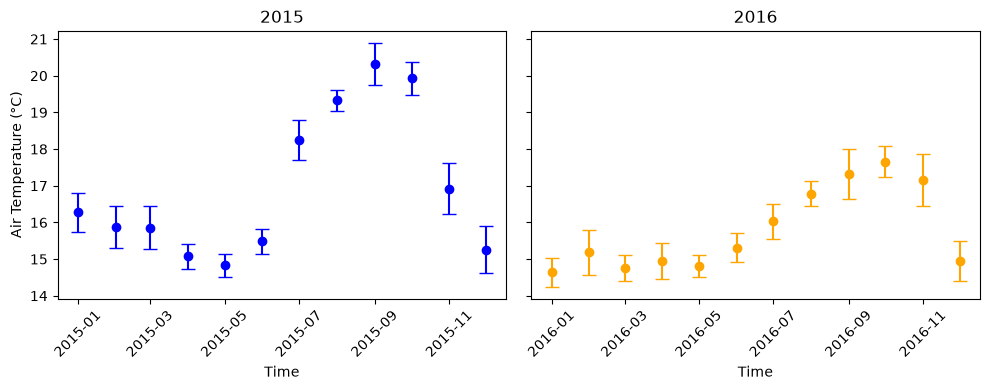

In [189]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), sharey =True)

ax1.errorbar(d15m_atemp[0], d15m_atemp[1], d15m_atemp[2], fmt='o', capsize=5, color='blue')
ax1.set_title('2015')
ax1.set_xlabel('Time')
ax1.set_ylabel('Air Temperature (°C)')

ax2.errorbar(d16m_atemp[0], d16m_atemp[1], d16m_atemp[2], fmt='o', capsize=5, color='orange')
ax2.set_title('2016')
ax2.set_xlabel('Time')

ax1.tick_params(axis='x', labelrotation=45)
ax2.tick_params(axis='x', labelrotation=45)
plt.tight_layout() 
plt.show()

# Question 3

In [190]:
type(d15_wspeed[0][0])

numpy.datetime64

In [191]:
d15_wspeed[1]

array([7.3, 7.2, 5.8, ..., 1.2, 2.0, 2.9], shape=(8746,), dtype=object)

In [192]:
def getCoef(arr):
    arr_range = np.arange(0, len(arr[0]), dtype = float)

    A = np.column_stack([np.ones_like(arr[0], dtype=float), list(range(0,len(arr[0])))])
    x, *_ = np.linalg.lstsq(A, arr[1].astype(float), rcond=None)
    fit_1 = A @ x
  
    # Model 2: add the annual cycle.
    A2 = np.column_stack([np.ones_like(arr[0], dtype=float), arr_range,
    np.sin(2*np.pi*arr_range/len(arr[0])), np.cos(2*np.pi*arr_range/len(arr[0]))])

    x2, *_ = np.linalg.lstsq(A2, arr[1].astype(float), rcond=None)
    fit_2 = A2 @ x2

    amp = np.sqrt(x2[2]**2+x2[3]**2)
    coefs = [x[0], x[1], amp]
    return coefs, fit_1, fit_2

In [193]:
def plotyears(yr1, yr2, yr1_f1, yr1_f2, yr2_f1, yr2_f2, name):
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), sharey =True)
    ax1.plot(yr1[0], yr1[1], lw=1, label='data')
    ax1.plot(yr1[0], yr1_f1, 'r', lw=2, label='mean + trend')
    ax1.plot(yr1[0], yr1_f2, 'k', lw=2, label='+ annual cycle')
    ax1.legend(loc='best')
    ax1.set_title("2015")
    ax1.set_xlabel('Time', fontsize=14); ax1.set_ylabel(name, fontsize=14)

    ax2.plot(yr2[0], yr2[1], lw=1, label='data')
    ax2.plot(yr2[0], yr2_f1, 'r', lw=2, label='mean + trend')
    ax2.plot(yr2[0], yr2_f2, 'k', lw=2, label='+ annual cycle')
    ax2.legend(loc='best')
    ax2.set_title("2016")
    ax2.set_xlabel('Time', fontsize=14)

    ax1.tick_params(axis='x', labelrotation=45)
    ax2.tick_params(axis='x', labelrotation=45)
    plt.tight_layout()
    plt.show()

1.712481012469658 0.7757379503562132


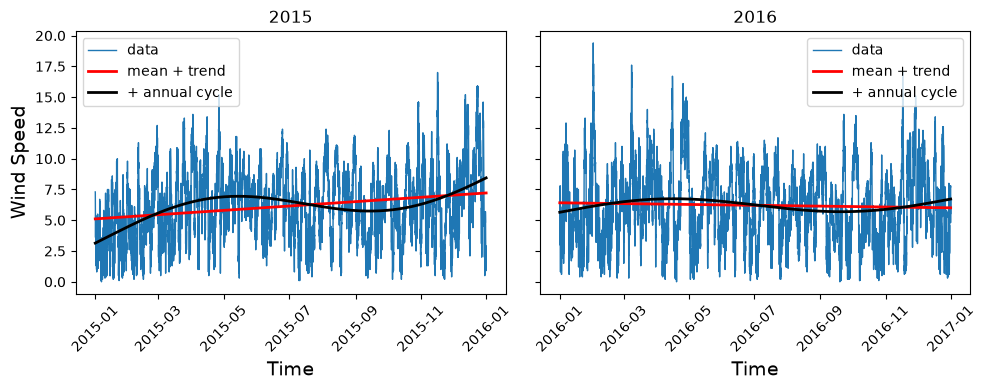

In [194]:
coefs15, fit15_1, fit15_2 = getCoef(d15_wspeed)
coefs16, fit16_1, fit16_2 = getCoef(d16_wspeed)
print(coefs15[2], coefs16[2])
plotyears(d15_wspeed,d16_wspeed,fit15_1,fit15_2,fit16_1,fit16_2,"Wind Speed")

0.6981018334329951 0.5354283238079953


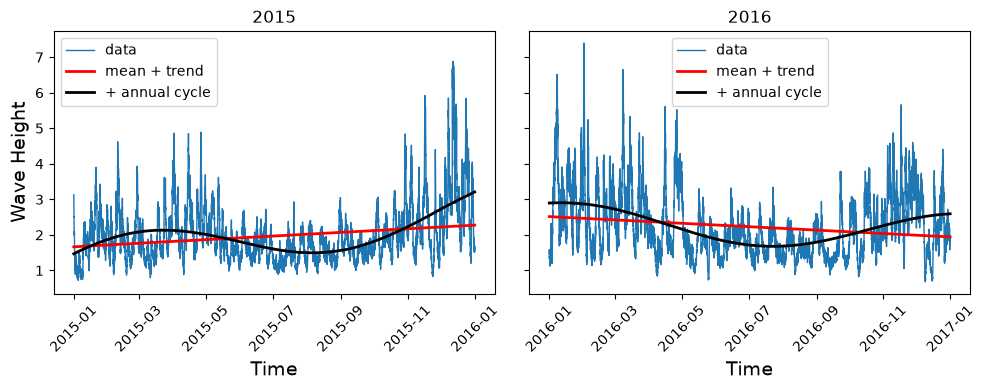

In [195]:
coefs15, fit15_1, fit15_2 = getCoef(d15_wah)
coefs16, fit16_1, fit16_2 = getCoef(d16_wah)
print(coefs15[2], coefs16[2])
plotyears(d15_wah,d16_wah,fit15_1,fit15_2,fit16_1,fit16_2,"Wave Height")


3.3436161621567004 1.4013528412935077


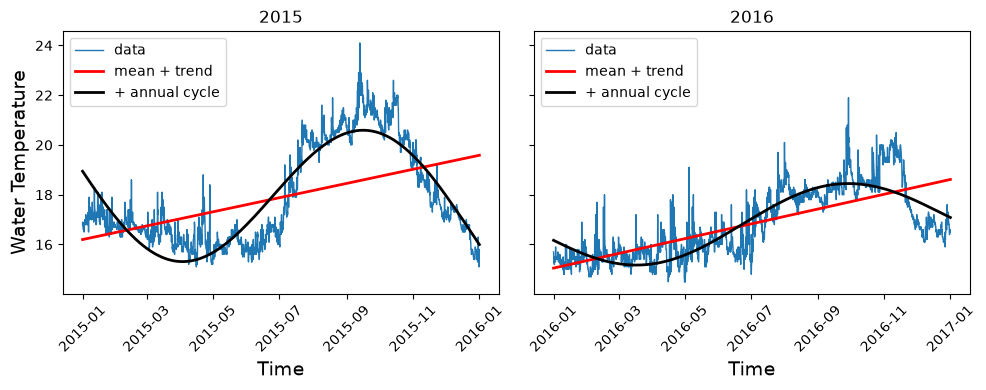

In [196]:
coefs15, fit15_1, fit15_2 = getCoef(d15_wtemp)
coefs16, fit16_1, fit16_2 = getCoef(d16_wtemp)
print(coefs15[2], coefs16[2])
plotyears(d15_wtemp,d16_wtemp,fit15_1,fit15_2,fit16_1,fit16_2,"Water Temperature")

3.50295372634072 1.4934376800658336


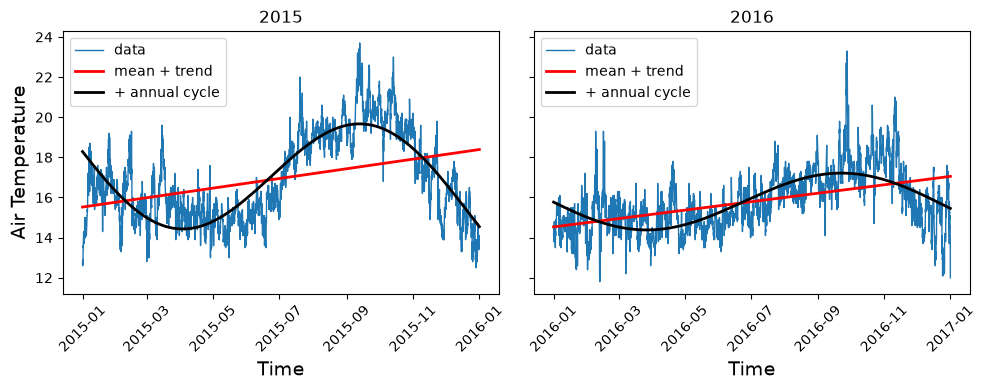

In [197]:
coefs15, fit15_1, fit15_2 = getCoef(d15_atemp)
coefs16, fit16_1, fit16_2 = getCoef(d16_atemp)
print(coefs15[2], coefs16[2])
plotyears(d15_atemp,d16_atemp,fit15_1,fit15_2,fit16_1,fit16_2,"Air Temperature")

The air and water temperatures are substantially different in terms of their amplitude, but the wave height and wind speed are pretty similar.

# Question 4

In [198]:
def getCoef(arr):
    arr_range = np.arange(0, len(arr[0]), dtype = float)

    A = np.column_stack([np.ones_like(arr[0], dtype=float), list(range(0,len(arr[0])))])
    x, *_ = np.linalg.lstsq(A, arr[1].astype(float), rcond=None)
    fit_1 = A @ x
  
    # Model 2: add the annual cycle.
    A2 = np.column_stack([np.ones_like(arr[0], dtype=float), arr_range,
    np.sin(2*np.pi*arr_range/len(arr[0])), np.cos(2*np.pi*arr_range/len(arr[0])), np.sin(4*np.pi*arr_range/len(arr[0])), np.cos(4*np.pi*arr_range/len(arr[0]))])

    x2, *_ = np.linalg.lstsq(A2, arr[1].astype(float), rcond=None)
    fit_2 = A2 @ x2

    amp = np.sqrt(x2[2]**2+x2[3]**2)
    sem_amp = np.sqrt(x2[4]**2+x2[5]**2)
    coefs = [x[0], x[1], amp, sem_amp]
    return coefs, fit_1, fit_2

In [199]:
def plotyears(yr1, yr2, yr1_f1, yr1_f2, yr2_f1, yr2_f2, name):
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), sharey =True)
    ax1.plot(yr1[0], yr1[1], lw=1, label='data')
    ax1.plot(yr1[0], yr1_f1, 'r', lw=2, label='mean + trend')
    ax1.plot(yr1[0], yr1_f2, 'k', lw=2, label='+ semi-annual cycle')
    ax1.legend(loc='best')
    ax1.set_title("2015")
    ax1.set_xlabel('Time', fontsize=14); ax1.set_ylabel(name, fontsize=14)

    ax2.plot(yr2[0], yr2[1], lw=1, label='data')
    ax2.plot(yr2[0], yr2_f1, 'r', lw=2, label='mean + trend')
    ax2.plot(yr2[0], yr2_f2, 'k', lw=2, label='+ semi-annual cycle')
    ax2.legend(loc='best')
    ax2.set_title("2016")
    ax2.set_xlabel('Time', fontsize=14)

    ax1.tick_params(axis='x', labelrotation=45)
    ax2.tick_params(axis='x', labelrotation=45)
    plt.tight_layout()
    plt.show()

1.8037872805350197 0.8495660097634464
semi-annual 0.2014909196958701 0.17561539219433092


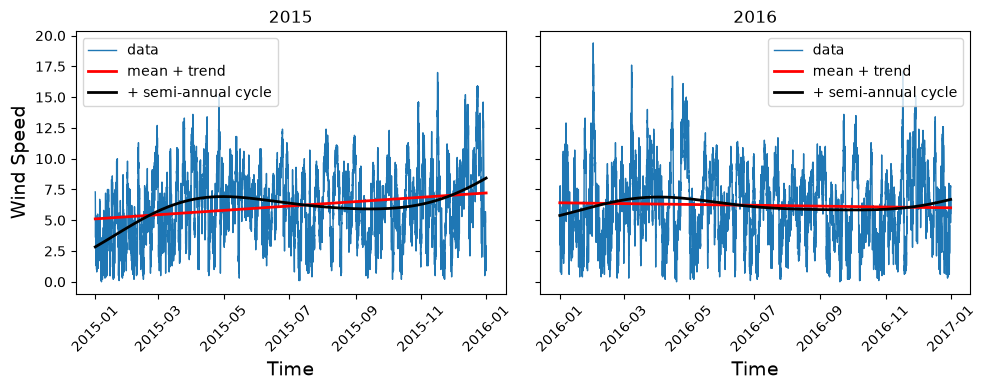

In [200]:
coefs15, fit15_1, fit15_2 = getCoef(d15_wspeed)
coefs16, fit16_1, fit16_2 = getCoef(d16_wspeed)
print(coefs15[2], coefs16[2])
print("semi-annual", coefs15[3], coefs16[3])
plotyears(d15_wspeed,d16_wspeed,fit15_1,fit15_2,fit16_1,fit16_2,"Wind Speed")


0.6633859843044337 0.5167132287296209
semi-annual 0.05502354166701573 0.17198168531925687


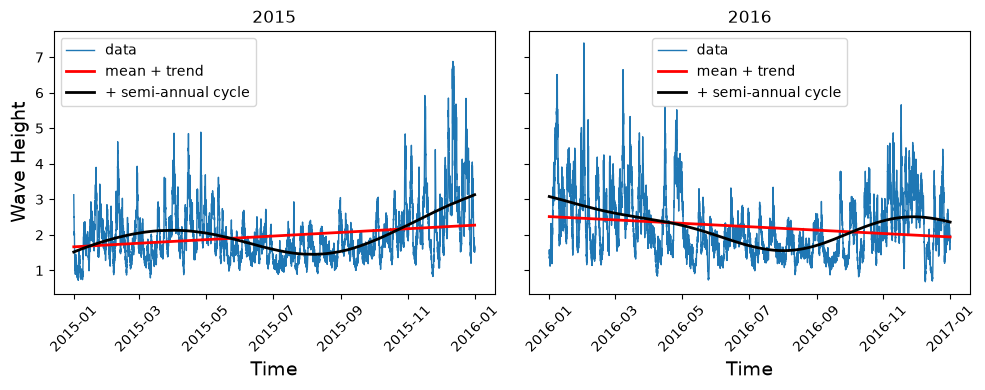

In [201]:
coefs15, fit15_1, fit15_2 = getCoef(d15_wah)
coefs16, fit16_1, fit16_2 = getCoef(d16_wah)
print(coefs15[2], coefs16[2])
print("semi-annual", coefs15[3], coefs16[3])
plotyears(d15_wah,d16_wah,fit15_1,fit15_2,fit16_1,fit16_2,"Wave Height")

2.8851039637892684 1.5047161964740685
semi-annual 1.0635160080927435 0.4762769715091759


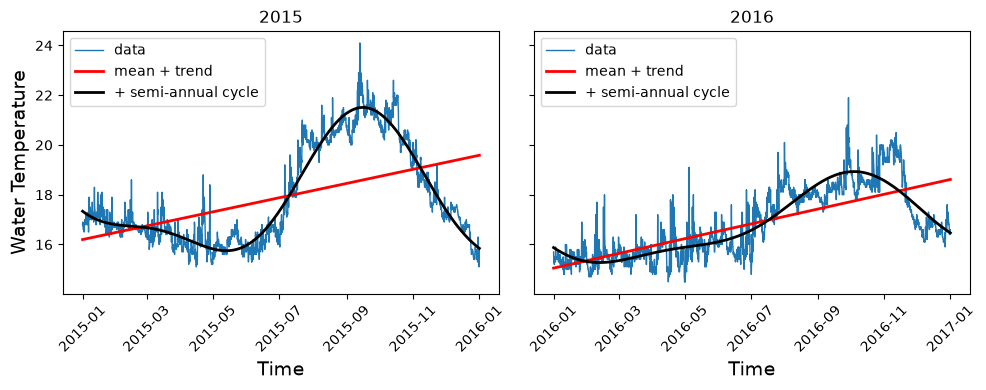

In [202]:
coefs15, fit15_1, fit15_2 = getCoef(d15_wtemp)
coefs16, fit16_1, fit16_2 = getCoef(d16_wtemp)
print(coefs15[2], coefs16[2])
print("semi-annual", coefs15[3], coefs16[3])
plotyears(d15_wtemp,d16_wtemp,fit15_1,fit15_2,fit16_1,fit16_2,"Water Temperature")

3.0259006331463425 1.5631824151613156
semi-annual 1.0987339772770415 0.6277928916700299


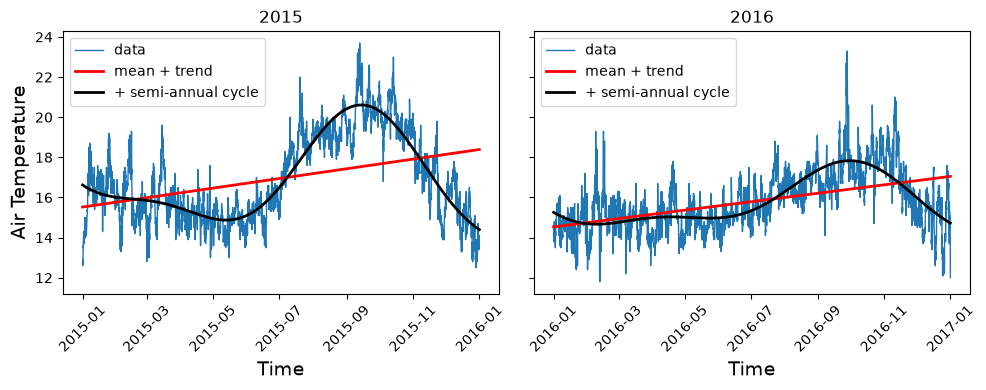

In [203]:
coefs15, fit15_1, fit15_2 = getCoef(d15_atemp)
coefs16, fit16_1, fit16_2 = getCoef(d16_atemp)
print(coefs15[2], coefs16[2])
print("semi-annual", coefs15[3], coefs16[3])
plotyears(d15_atemp,d16_atemp,fit15_1,fit15_2,fit16_1,fit16_2,"Air Temperature")

The augmented least squares gives a slightly different amplitude of the annual cycle, but not terribly different. The values for the amplitudes of the semi-annual cycle are shown above the graphs. 

# Question 5

In [204]:
def getChiSquaredMisfit(arr, sigma=None):
    N = len(arr[1])
    arr_range = np.arange(0, N, dtype=float)
    y_target = arr[1].astype(float)

    A1 = np.column_stack([
            np.ones(N, dtype=float), 
            arr_range,
            np.sin(2 * np.pi * arr_range / N), 
            np.cos(2 * np.pi * arr_range / N)
        ])
        
    x1, *_ = np.linalg.lstsq(A1, y_target, rcond=None)
    fit_1 = A1 @ x1

    A2 = np.column_stack([
        np.ones(N, dtype=float), 
        arr_range,
        np.sin(2 * np.pi * arr_range / N), 
        np.cos(2 * np.pi * arr_range / N), 
        np.sin(4 * np.pi * arr_range / N), 
        np.cos(4 * np.pi * arr_range / N)
    ])
    
    M = A2.shape[1] 
    
    x2, *_ = np.linalg.lstsq(A2, y_target, rcond=None)
    fit_2 = A2 @ x2

    sigma = np.ones(N)

    chi_squared_semi = np.sum(((y_target - fit_2) / sigma) ** 2)
    chi_squared_an = np.sum(((y_target - fit_1) / sigma) ** 2)

    return chi_squared_semi, chi_squared_an


Wind Speed

In [205]:
ch15_ws_s, ch15_ws_a = getChiSquaredMisfit(d15_wspeed)
print(ch15_ws_s,ch15_ws_a)

62929.61737563707 63082.54875669749


In [206]:
ch16_ws_s, ch16_ws_a = getChiSquaredMisfit(d16_wspeed)
print(ch16_ws_s,ch16_ws_a)

78652.64517068087 78771.53261046493


Wave Height

In [207]:
ch15_wah_s, ch15_wah_a = getChiSquaredMisfit(d15_wah)
print(ch15_wah_s,ch15_wah_a)
ch16_wah_s, ch16_wah_a = getChiSquaredMisfit(d16_wah)
print(ch16_wah_s,ch16_wah_a)

3772.781747930616 3780.8631403146387
5595.2917555762715 5674.725883942032


Water Temperature

In [208]:
ch15_wt_s, ch15_wt_a = getChiSquaredMisfit(d15_wtemp)
print(ch15_wt_s,ch15_wt_a)
ch16_wt_s, ch16_wt_a = getChiSquaredMisfit(d16_wtemp)
print(ch16_wt_s,ch16_wt_a)

2343.7382450086225 6675.919719593947
3455.463738048539 4411.619795236529


Air Temperature

In [209]:
ch15_at_s, ch15_at_a = getChiSquaredMisfit(d15_atemp)
print(ch15_at_s,ch15_at_a)
ch16_at_s, ch16_at_a = getChiSquaredMisfit(d16_atemp)
print(ch16_at_s,ch16_at_a)

8297.361229052165 12910.635384766074
8524.615379659783 10225.804089449815


The values are fairly similar between the chisquared values for the semi annual and annual fits. There are a few with large differences, including 2015's water temperature (triple the chi-squared for an annual fit) and 2015's air temperature (50% larger value).

I ran out of time to finish the chi-squared distribution part. These chi-squared values honestly look way too high but I'm not sure what standard deviation we should be using per point. It also is not the reduced chi-squared statistic, which could be why the values are so large.